# Praktikum Minggu 12 Sesi 2 & 3 — RNN dan LSTM
**Mata Kuliah:** Kecerdasan Buatan  
**Nama:** Tika Altiora Sitanggang  
**NIM:** 42324025  
**Materi:** Recurrent Neural Network (RNN) dan Long Short-Term Memory (LSTM)  
**Dataset:** Advance Retail Sales: Retail (excluding food services) — `RSCCASN.csv`  

---
**Tujuan:** memahami konsep dan mengimplementasikan algoritma RNN dan LSTM untuk memprediksi data *time series* penjualan ritel bulanan.

**Alur praktikum:**
1. Persiapan lingkungan pengembangan
2. Unduh/muat dataset dan pengolahan data
3. Normalisasi data
4. Membuat Time Series Generator
5. Membangun model RNN dan LSTM
6. Evaluasi model dan prediksi data uji
7. Prediksi jangka panjang (forecast 12 bulan ke depan)

## Landasan Teori Singkat

**Time Series** adalah data yang diukur pada interval waktu teratur (harian, mingguan, bulanan) dan urutan waktunya sangat penting. Karakteristiknya: *Trend* (pergerakan jangka panjang), *Seasonality* (pola berulang pada periode tetap), *Cyclical* (fluktuasi jangka panjang yang tidak berulang tetap), dan *Random/Noise* (variasi acak).

**Recurrent Neural Network (RNN)** adalah neural network untuk data sekuensial. RNN memproses elemen urutan satu per satu dan menyimpan memori dari langkah sebelumnya pada *hidden state* yang diperbarui di setiap *time step*. Bobot matriks **U** menghubungkan input dengan hidden state, **W** menghubungkan hidden state antar time step, dan **V** menghubungkan hidden state dengan output. Tipe RNN: *one to one*, *one to many*, *many to one*, dan *many to many*. Pada praktikum ini digunakan tipe **many to one** (12 bulan sebelumnya → 1 bulan berikutnya).

**Tantangan RNN:** *short-term* dan *long-term dependencies* yang disebabkan oleh *exploding* dan *vanishing gradients*. Jika nilai singular terbesar dari perkalian gradien > 1 terjadi exploding gradients, jika < 1 terjadi vanishing gradients.

**Long Short-Term Memory (LSTM)** (Hochreiter & Schmidhuber, 1997) mengatasi masalah tersebut dengan *cell state* sebagai memori jangka panjang yang diperbarui secara aditif, serta tiga gate:
- **Forget gate:** $f_t = \sigma(W_f \cdot [h_{t-1}, x_t] + b_f)$ — menentukan informasi $C_{t-1}$ yang dibuang.
- **Input gate:** $i_t = \sigma(W_i \cdot [h_{t-1}, x_t] + b_i)$ dan $\tilde{C}_t = \tanh(W_C \cdot [h_{t-1}, x_t] + b_C)$ — mengatur informasi baru yang ditambahkan.
- **Cell state:** $C_t = f_t * C_{t-1} + i_t * \tilde{C}_t$ — memperbarui memori.
- **Output gate:** $o_t = \sigma(W_o [h_{t-1}, x_t] + b_o)$ dan $h_t = o_t * \tanh(C_t)$ — menghasilkan hidden state.

Kekurangan LSTM: pelatihan lebih lambat dan kompleksitas komputasi lebih tinggi, terutama pada dataset besar.

## 1. Persiapan Lingkungan Pengembangan

Praktikum dikerjakan di **Google Colab** karena library deep learning (TensorFlow, Keras, NumPy, Matplotlib, dll.) sudah tersedia. Sel berikut meng-install/memastikan TensorFlow tersedia.

In [19]:
!pip install -q tensorflow

**Import library yang dibutuhkan:**
- `numpy`, `pandas` untuk manipulasi data; `matplotlib`, `seaborn` untuk visualisasi.
- `tensorflow`/`keras` untuk membangun model (`Sequential`, `SimpleRNN`, `LSTM`, `Dense`, `Dropout`) dan callback `EarlyStopping`.
- `TimeseriesGenerator` untuk membuat pasangan input-target sekuensial.
- `MinMaxScaler` (scikit-learn) untuk normalisasi.
- `matplotlib.dates` untuk format sumbu tanggal pada plot.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Dropout
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.dates as mdates

# TimeseriesGenerator (dengan cadangan jika tidak tersedia di versi Keras yang dipakai)
try:
    from tensorflow.keras.preprocessing.sequence import TimeseriesGenerator
except ImportError:
    class TimeseriesGenerator(tf.keras.utils.Sequence):
        def __init__(self, data, targets, length, batch_size=1, **kwargs):
            super().__init__(**kwargs)
            self.data, self.targets = np.asarray(data), np.asarray(targets)
            self.length, self.batch_size = length, batch_size
        def __len__(self):
            return int(np.ceil((len(self.data) - self.length) / self.batch_size))
        def __getitem__(self, idx):
            start = idx * self.batch_size
            end = min(start + self.batch_size, len(self.data) - self.length)
            X = np.array([self.data[i:i + self.length] for i in range(start, end)])
            y = np.array([self.targets[i + self.length] for i in range(start, end)])
            return X, y

print("TensorFlow versi:", tf.__version__)

TensorFlow versi: 2.22.0-rc0


## 2. Unduh Dataset

Dataset **Retail Sales** (`RSCCASN.csv`) diunduh dari tautan pada modul, lalu diunggah ke Google Colab (ikon *Files* → *Upload*). Sel berikut mengecek apakah file sudah ada; jika belum, akan muncul dialog untuk mengunggah file.

In [21]:
import os
if not os.path.exists('RSCCASN.csv'):
    from google.colab import files
    uploaded = files.upload()   # pilih file RSCCASN.csv
print("File ditemukan:", os.path.exists('RSCCASN.csv'))

File ditemukan: True


## 2. Pengolahan Data (Data Processing)

Langkah pada sel berikut:
- Memuat dataset **Retail Sales** dengan kolom `DATE` sebagai index bertipe tanggal (`parse_dates=True`, `index_col='DATE'`).
- Mengubah nama kolom asli (`RSCCASN`) menjadi `'Sales'`.
- Menampilkan data penjualan menggunakan plot.

            Sales
DATE             
1992-01-01   6938
1992-02-01   7524
1992-03-01   8475
1992-04-01   9401
1992-05-01   9558

Jumlah data: 334 bulan
Rentang waktu: 1992-01-01 s/d 2019-10-01


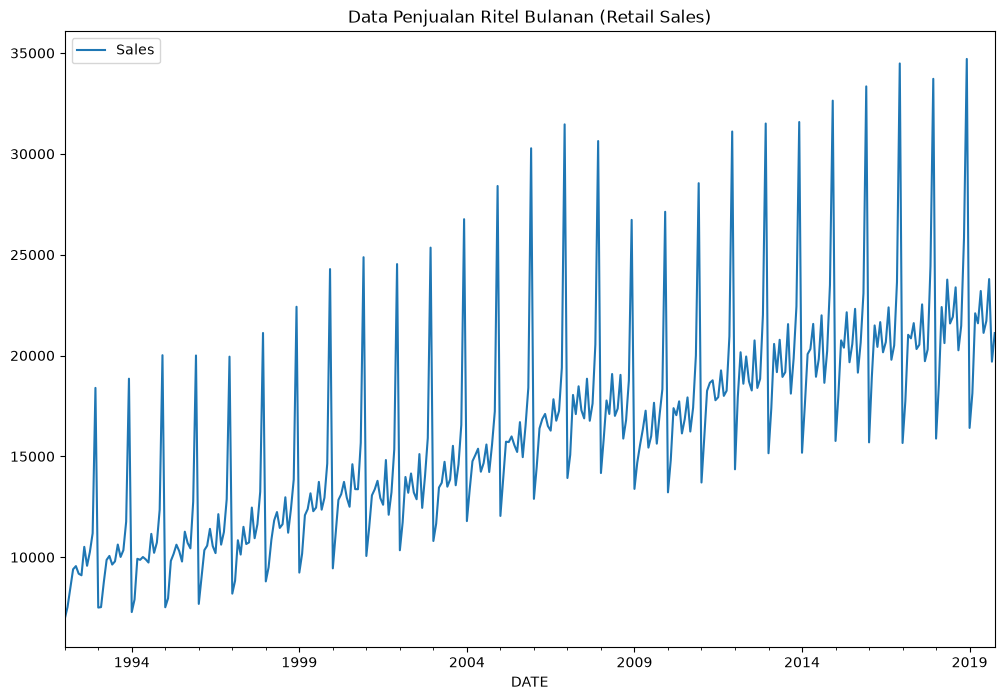

In [22]:
# Membaca dataset
dataset_path = 'RSCCASN.csv'
sales_data = pd.read_csv(dataset_path, parse_dates=True, index_col='DATE')
sales_data.columns = ['Sales']

# Melihat sekilas data
print(sales_data.head())
print("\nJumlah data:", len(sales_data), "bulan")
print("Rentang waktu:", sales_data.index[0].date(), "s/d", sales_data.index[-1].date())

# Plot data penjualan
sales_data.plot(figsize=(12, 8))
plt.title('Data Penjualan Ritel Bulanan (Retail Sales)')
plt.show()

**Penjelasan hasil:** plot memperlihatkan *trend* naik jangka panjang dan *seasonality* tahunan yang jelas (lonjakan tajam setiap akhir tahun/Desember), sesuai karakteristik time series pada teori.

**Pembagian data (Train-Test Split):** data deret waktu tidak boleh diacak, sehingga 18 bulan terakhir dipakai sebagai data uji (`test_size = 18`) dan sisanya sebagai data latih. `iloc` digunakan untuk memotong berdasarkan posisi baris.

In [23]:
# Train-test split
test_size = 18
test_index = len(sales_data) - test_size
train = sales_data.iloc[:test_index]
test = sales_data.iloc[test_index:].copy()   # .copy() agar kolom prediksi dapat ditambahkan tanpa warning

print("Data latih :", train.shape, "->", train.index[0].date(), "s/d", train.index[-1].date())
print("Data uji   :", test.shape, "->", test.index[0].date(), "s/d", test.index[-1].date())

Data latih : (316, 1) -> 1992-01-01 s/d 2018-04-01
Data uji   : (18, 1) -> 2018-05-01 s/d 2019-10-01


## 3. Normalisasi Data

- **Inisialisasi `MinMaxScaler`:** menskalakan data ke rentang 0–1 agar pelatihan jaringan saraf lebih stabil.
- **`scaler.fit(train)`:** menghitung nilai minimum dan maksimum **hanya dari data latih** (mencegah kebocoran informasi dari data uji).
- **`scaler.transform`:** mentransformasikan data latih dan data uji berdasarkan skala yang telah dihitung.

In [24]:
# Inisialisasi MinMaxScaler
scaler = MinMaxScaler()
scaler.fit(train)

# Transformasi data train dan test
scaled_train = scaler.transform(train)
scaled_test = scaler.transform(test)

print("Min-Max data latih  :", scaled_train.min(), "-", scaled_train.max())
print("Min-Max data uji    :", scaled_test.min(), "-", scaled_test.max())

Min-Max data latih  : 0.0 - 1.0
Min-Max data uji    : 0.3438861458030787 - 1.0081324426372351


## 4. Membuat Time Series Generator

- **Panjang sekuens (`length = 12`):** setiap sampel memakai 12 bulan sebelumnya sebagai input.
- **`TimeseriesGenerator`:** membentuk pasangan input (X) berupa jendela 12 bulan dan target (y) berupa nilai bulan berikutnya.
- **`n_features = 1`:** hanya ada satu fitur, yaitu `Sales`.
- `batch_size=1` berarti satu sampel per langkah pelatihan.

In [25]:
# Membuat generator data time series
length = 12  # Panjang input (12 bulan)
n_features = 1
generator = TimeseriesGenerator(scaled_train, scaled_train, length=length, batch_size=1)

# Memeriksa satu contoh pasangan input-target
X, y = generator[0]
print("Jumlah batch/sampel latih :", len(generator))
print("Bentuk X :", X.shape, "(batch, time step, fitur)")
print("Bentuk y :", y.shape)

Jumlah batch/sampel latih : 304
Bentuk X : (1, 12, 1) (batch, time step, fitur)
Bentuk y : (1, 1)


## 5. Membangun Model RNN

- **Arsitektur:** satu layer `SimpleRNN` dengan 100 unit (aktivasi ReLU) diikuti layer `Dense(1)` sebagai output prediksi.
- **Kompilasi:** optimizer `adam`, fungsi loss `mse` (Mean Squared Error).
- **Early Stopping:** pelatihan dihentikan bila `val_loss` tidak membaik selama 3 epoch (`patience=3`), dan bobot terbaik dikembalikan (`restore_best_weights=True`).
- **Validation generator:** dibuat dari data uji yang sudah diskalakan.
- **Pelatihan:** maksimal 20 epoch dengan data validasi.

In [26]:
# Model SimpleRNN
model_rnn = Sequential()
model_rnn.add(SimpleRNN(100, activation='relu', input_shape=(length, n_features)))
model_rnn.add(Dense(1))
model_rnn.compile(optimizer='adam', loss='mse')
model_rnn.summary()

c:\Users\tikas\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn_1 (SimpleRNN)        │ (None, 100)            │        10,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,301 (40.24 KB)

 Trainable params: 10,301 (40.24 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
# Callback early stopping untuk RNN
early_stop_rnn = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

# Validation generator
validation_generator = TimeseriesGenerator(scaled_test, scaled_test, length=length, batch_size=1)

# Melatih model RNN
history_rnn = model_rnn.fit(generator, epochs=20, validation_data=validation_generator,
                            callbacks=[early_stop_rnn], verbose=2)

Epoch 1/20
304/304 - 2s - 5ms/step - loss: 0.0220 - val_loss: 0.0130
Epoch 2/20
304/304 - 1s - 3ms/step - loss: 0.0078 - val_loss: 8.0201e-04
Epoch 3/20
304/304 - 1s - 3ms/step - loss: 0.0021 - val_loss: 0.0014
Epoch 4/20
304/304 - 1s - 2ms/step - loss: 0.0023 - val_loss: 8.3119e-04
Epoch 5/20
304/304 - 1s - 2ms/step - loss: 0.0017 - val_loss: 0.0013


## 5. Membangun Model LSTM

- **Arsitektur:** layer `LSTM` 100 unit, `Dropout(0.2)` untuk mengurangi overfitting, lalu `Dense(1)` sebagai output.
- **Kompilasi:** optimizer Adam dengan learning rate 0.001 dan loss `mse`.
- **Early Stopping:** berhenti bila `val_loss` tidak membaik selama 5 epoch (`patience=5`).
- **Pelatihan:** maksimal 20 epoch dengan data validasi yang sama.

In [28]:
# Model LSTM dengan penambahan Dropout
model_lstm = Sequential()
model_lstm.add(LSTM(100, activation='relu', input_shape=(length, n_features)))
model_lstm.add(Dropout(0.2))  # Penambahan Dropout untuk mengurangi overfitting
model_lstm.add(Dense(1))
model_lstm.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001), loss='mse')
model_lstm.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 100)            │        40,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           101 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 40,901 (159.77 KB)

 Trainable params: 40,901 (159.77 KB)

 Non-trainable params: 0 (0.00 B)

In [29]:
# Callback early stopping untuk LSTM
early_stop_lstm = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

# Melatih model LSTM
history_lstm = model_lstm.fit(generator, epochs=20, validation_data=validation_generator,
                              callbacks=[early_stop_lstm], verbose=2)

Epoch 1/20
304/304 - 2s - 6ms/step - loss: 0.0232 - val_loss: 0.0026
Epoch 2/20
304/304 - 1s - 3ms/step - loss: 0.0179 - val_loss: 0.0495
Epoch 3/20
304/304 - 1s - 3ms/step - loss: 0.0130 - val_loss: 0.0010
Epoch 4/20
304/304 - 2s - 5ms/step - loss: 0.0070 - val_loss: 0.0051
Epoch 5/20
304/304 - 1s - 4ms/step - loss: 0.0063 - val_loss: 0.0131
Epoch 6/20
304/304 - 1s - 3ms/step - loss: 0.0042 - val_loss: 0.0324
Epoch 7/20
304/304 - 1s - 3ms/step - loss: 0.0046 - val_loss: 0.0019
Epoch 8/20
304/304 - 1s - 3ms/step - loss: 0.0025 - val_loss: 7.4585e-04
Epoch 9/20
304/304 - 1s - 3ms/step - loss: 0.0031 - val_loss: 2.5780e-04
Epoch 10/20
304/304 - 1s - 3ms/step - loss: 0.0030 - val_loss: 1.5895e-04
Epoch 11/20
304/304 - 1s - 3ms/step - loss: 0.0034 - val_loss: 2.6189e-04
Epoch 12/20
304/304 - 1s - 3ms/step - loss: 0.0025 - val_loss: 2.2779e-04
Epoch 13/20
304/304 - 1s - 3ms/step - loss: 0.0025 - val_loss: 3.9136e-04
Epoch 14/20
304/304 - 1s - 3ms/step - loss: 0.0014 - val_loss: 0.0056
Epoch

**Penjelasan arsitektur:** parameter LSTM (≈40.800) sekitar 4× lebih banyak daripada SimpleRNN (≈10.200) pada jumlah unit yang sama karena LSTM memiliki empat set bobot (forget gate, input gate, candidate cell state, dan output gate), sedangkan SimpleRNN hanya satu.

## 6. Evaluasi Model dan Prediksi

**Fungsi untuk evaluasi loss:** `plot_loss` memvisualisasikan *training loss* dan *validation loss* dari kedua model (RNN dan LSTM) dalam satu grafik untuk memantau overfitting atau underfitting.

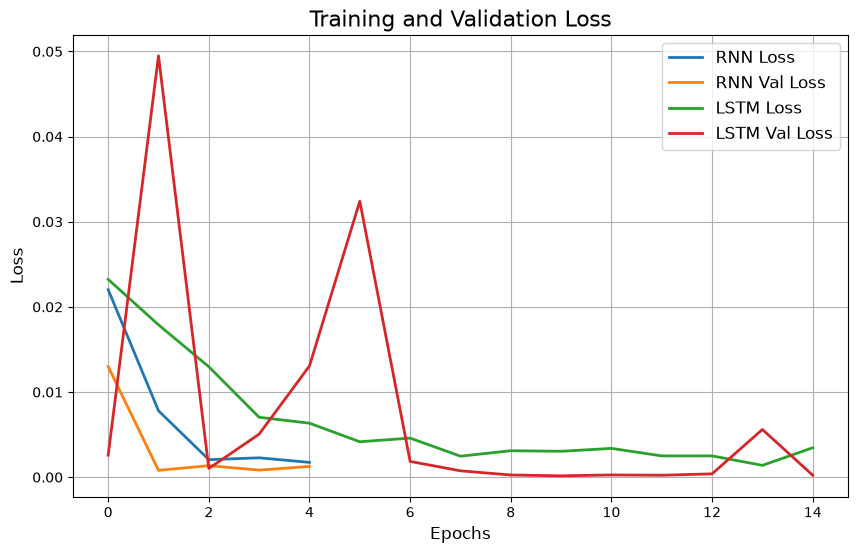

In [30]:
# Fungsi untuk plot training dan validation loss
def plot_loss(history_rnn, history_lstm):
    # Plot the training and validation loss
    losses_rnn = pd.DataFrame(history_rnn.history)
    losses_lstm = pd.DataFrame(history_lstm.history)

    plt.figure(figsize=(10, 6))
    plt.plot(losses_rnn['loss'], label='RNN Loss', linewidth=2)
    plt.plot(losses_rnn['val_loss'], label='RNN Val Loss', linewidth=2)
    plt.plot(losses_lstm['loss'], label='LSTM Loss', linewidth=2)
    plt.plot(losses_lstm['val_loss'], label='LSTM Val Loss', linewidth=2)
    plt.title('Training and Validation Loss', fontsize=16)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()

plot_loss(history_rnn, history_lstm)

**Plot loss per model:** fungsi `plot_loss_rnn` dan `plot_loss_lstm` menampilkan kurva loss dan validation loss untuk masing-masing model secara terpisah, sehingga perilaku pelatihan tiap model lebih mudah dibandingkan.

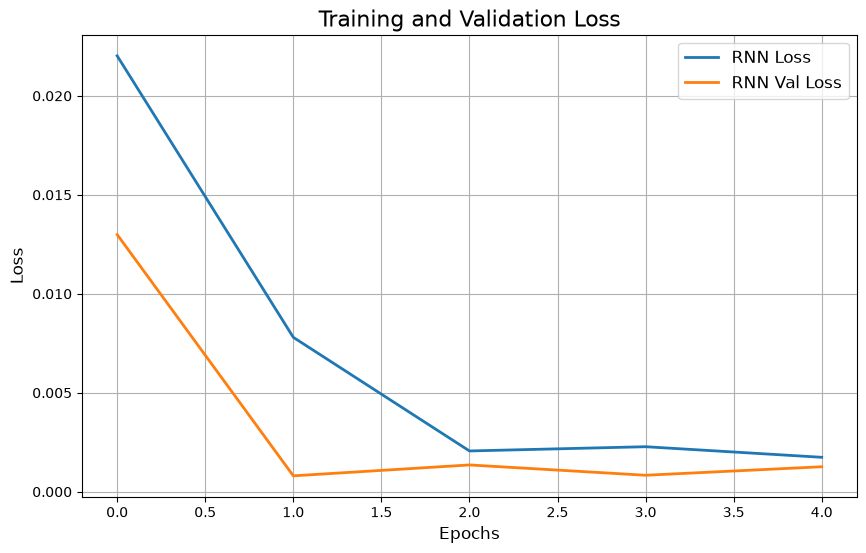

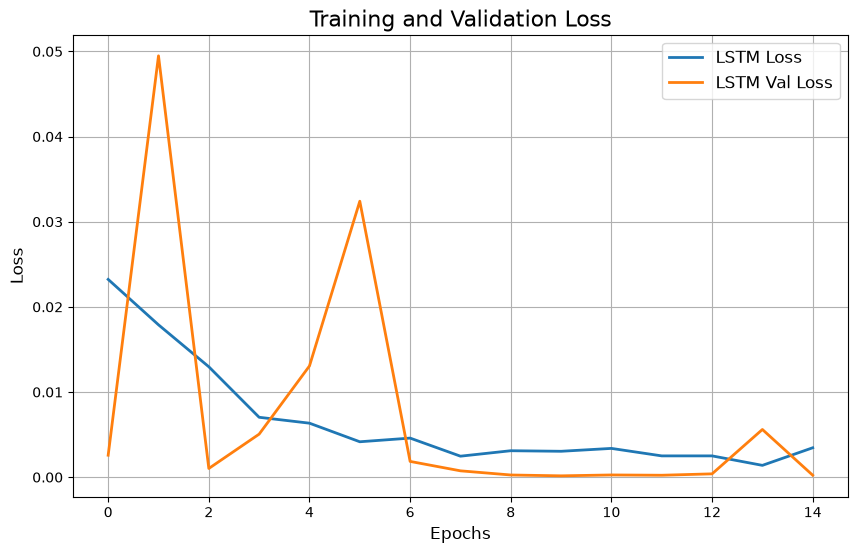

In [31]:
def plot_loss_rnn(history_rnn):
    # Plot the training and validation loss
    losses_rnn = pd.DataFrame(history_rnn.history)

    plt.figure(figsize=(10, 6))
    plt.plot(losses_rnn['loss'], label='RNN Loss', linewidth=2)
    plt.plot(losses_rnn['val_loss'], label='RNN Val Loss', linewidth=2)
    plt.title('Training and Validation Loss', fontsize=16)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()

def plot_loss_lstm(history_lstm):
    # Plot the training and validation loss
    losses_lstm = pd.DataFrame(history_lstm.history)

    plt.figure(figsize=(10, 6))
    plt.plot(losses_lstm['loss'], label='LSTM Loss', linewidth=2)
    plt.plot(losses_lstm['val_loss'], label='LSTM Val Loss', linewidth=2)
    plt.title('Training and Validation Loss', fontsize=16)
    plt.xlabel('Epochs', fontsize=12)
    plt.ylabel('Loss', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()

plot_loss_rnn(history_rnn)
plot_loss_lstm(history_lstm)

**Prediksi model pada data uji:** fungsi `make_predictions` melakukan prediksi *rekursif*: dimulai dari 12 bulan terakhir data latih, model memprediksi satu bulan, lalu hasil prediksi dimasukkan ke jendela input (menggeser jendela satu langkah) untuk memprediksi bulan berikutnya, sebanyak `len(test)` kali. Hasil prediksi dikembalikan ke skala asli dengan `scaler.inverse_transform`, lalu ditambahkan ke DataFrame `test`.

In [32]:
# Membuat prediksi untuk data test dengan RNN dan LSTM
def make_predictions(model, scaled_data, length, n_features):
    predictions = []
    first_eval_batch = scaled_data[-length:]
    current_batch = first_eval_batch.reshape((1, length, n_features))

    for i in range(len(test)):
        current_pred = model.predict(current_batch, verbose=0)[0]
        predictions.append(current_pred)
        current_batch = np.append(current_batch[:, 1:, :], [[current_pred]], axis=1)

    return scaler.inverse_transform(predictions)

rnn_predictions = make_predictions(model_rnn, scaled_train, length, n_features)
lstm_predictions = make_predictions(model_lstm, scaled_train, length, n_features)

# Menambahkan prediksi ke dataframe test
test['RNN_Predictions'] = rnn_predictions
test['LSTM_Predictions'] = lstm_predictions
test

,Sales,RNN_Predictions,LSTM_Predictions
DATE,,,
2018-05-01,23764,21566.791740,21158.360375
2018-06-01,21589,19870.408057,19662.495153
2018-07-01,21919,20939.337746,20004.292797
2018-08-01,23381,21942.947935,22367.849339
2018-09-01,20260,18923.581087,19207.456959
2018-10-01,21473,19708.729305,20077.736499
2018-11-01,25831,22202.283743,24859.891726
2018-12-01,34706,31267.218072,35708.929278
2019-01-01,16410,15438.077813,14782.338923


**Plot prediksi:** fungsi `plot_predictions` membandingkan penjualan aktual (biru) dengan prediksi RNN (oranye putus-putus) dan LSTM (hijau putus-putus) pada periode data uji. Sumbu-x diformat per 3 bulan agar tanggal terbaca jelas.

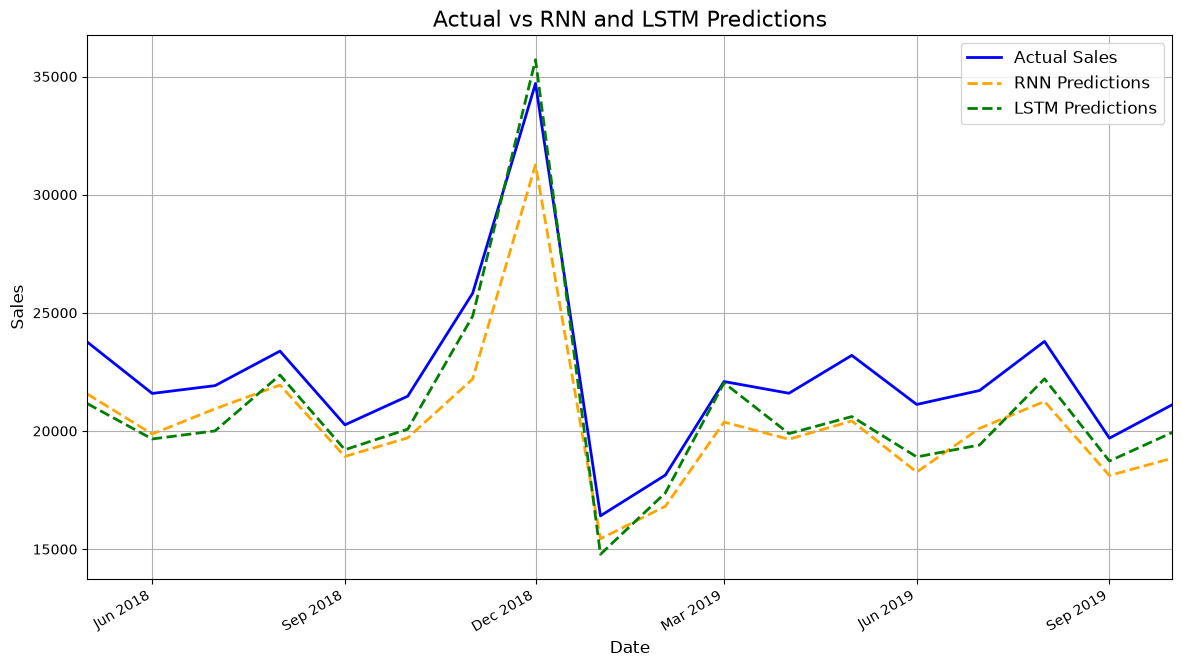

In [33]:
# Fungsi untuk plot prediksi RNN dan LSTM bersama data actual
def plot_predictions(test, sales_data, rnn_predictions, lstm_predictions):
    # Plot RNN and LSTM predictions along with actual sales
    plt.figure(figsize=(14, 8))
    plt.plot(test.index, test['Sales'], label='Actual Sales', color='blue', linewidth=2)
    plt.plot(test.index, test['RNN_Predictions'], label='RNN Predictions', color='orange', linestyle='--', linewidth=2)
    plt.plot(test.index, test['LSTM_Predictions'], label='LSTM Predictions', color='green', linestyle='--', linewidth=2)

    # Formatting the x-axis to show dates nicely
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    plt.gcf().autofmt_xdate()  # Rotate the x labels for better readability

    plt.title('Actual vs RNN and LSTM Predictions', fontsize=16)
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Sales', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.xlim([test.index[0], test.index[-1]])
    plt.show()

plot_predictions(test, sales_data, rnn_predictions, lstm_predictions)

**Metrik evaluasi (tambahan):** untuk membandingkan kedua model secara kuantitatif, dihitung *Root Mean Squared Error* (RMSE) dan *Mean Absolute Error* (MAE) antara penjualan aktual dan prediksi pada data uji. Semakin kecil nilainya, semakin baik modelnya.

In [34]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

hasil = []
for nama, kolom in [('RNN', 'RNN_Predictions'), ('LSTM', 'LSTM_Predictions')]:
    rmse = np.sqrt(mean_squared_error(test['Sales'], test[kolom]))
    mae = mean_absolute_error(test['Sales'], test[kolom])
    hasil.append({'Model': nama, 'RMSE': round(rmse, 2), 'MAE': round(mae, 2)})

df_hasil = pd.DataFrame(hasil).set_index('Model')
print(df_hasil)
print("\nModel dengan RMSE terendah:", df_hasil['RMSE'].idxmin())

          RMSE      MAE
Model                  
RNN    2142.88  2004.42
LSTM   1634.82  1492.56

Model dengan RMSE terendah: LSTM


## 7. Prediksi Jangka Panjang (Forecast)

Fungsi `forecast_future` bekerja seperti `make_predictions`, tetapi memprediksi sejumlah `periods` bulan **ke masa depan** (di luar data yang ada) secara rekursif. Di sini diprediksi **12 periode (bulan) ke depan** dengan kedua model, lalu dibuat DataFrame dengan indeks tanggal bulanan (`freq='MS'`, awal bulan) mulai `2019-11-01`.

In [35]:
# Membuat prediksi ke depan dengan model
def forecast_future(model, scaled_data, length, n_features, periods):
    forecast = []
    first_eval_batch = scaled_data[-length:]
    current_batch = first_eval_batch.reshape((1, length, n_features))

    for i in range(periods):
        current_pred = model.predict(current_batch, verbose=0)[0]
        forecast.append(current_pred)
        current_batch = np.append(current_batch[:, 1:, :], [[current_pred]], axis=1)

    return scaler.inverse_transform(forecast)

# Prediksi untuk 12 periode ke depan
forecast_rnn = forecast_future(model_rnn, scaled_train, length, n_features, periods=12)
forecast_lstm = forecast_future(model_lstm, scaled_train, length, n_features, periods=12)

# Membuat dataframe untuk forecast
forecast_index = pd.date_range(start='2019-11-01', periods=12, freq='MS')
forecast_rnn_data = pd.DataFrame(data=forecast_rnn, index=forecast_index, columns=['RNN_Forecast'])
forecast_lstm_data = pd.DataFrame(data=forecast_lstm, index=forecast_index, columns=['LSTM_Forecast'])

print(pd.concat([forecast_rnn_data, forecast_lstm_data], axis=1))

            RNN_Forecast  LSTM_Forecast
2019-11-01  21566.791740   21158.360375
2019-12-01  19870.408057   19662.495153
2020-01-01  20939.337746   20004.292797
2020-02-01  21942.947935   22367.849339
2020-03-01  18923.581087   19207.456959
2020-04-01  19708.729305   20077.736499
2020-05-01  22202.283743   24859.891726
2020-06-01  31267.218072   35708.929278
2020-07-01  15438.077813   14782.338923
2020-08-01  16812.935364   17382.703176
2020-09-01  20378.001964   22036.931575
2020-10-01  19650.811637   19890.230551


## 7. Plot Forecast

Fungsi `plot_forecast`:
1. Mengambil nilai dan tanggal terakhir dari data aktual.
2. Menyesuaikan indeks waktu forecast agar dimulai tepat satu bulan setelah data aktual terakhir.
3. Menambahkan nilai aktual terakhir sebagai titik awal garis forecast agar grafik tersambung.
4. Menggabungkan data aktual dan prediksi (`pd.concat`).
5. Memvisualisasikan penjualan aktual beserta forecast RNN dan LSTM dengan batas sumbu-x Januari 2018 – Desember 2020.

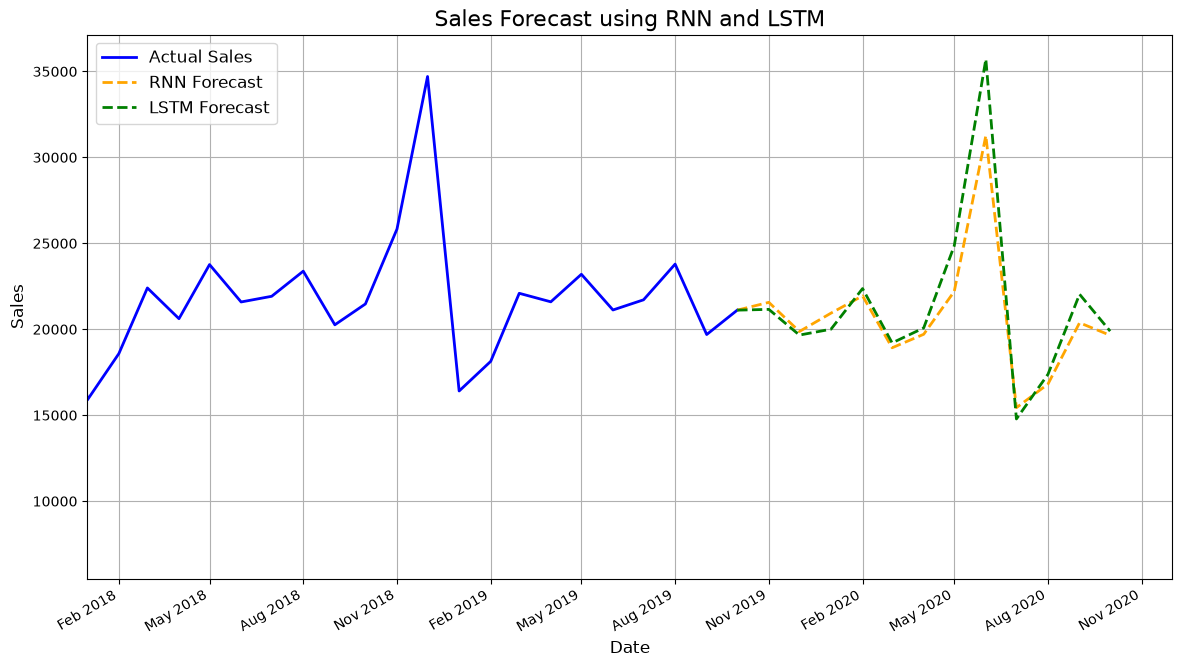

In [36]:
# Fungsi untuk plot forecast ke depan
def plot_forecast(sales_data, forecast_rnn_data, forecast_lstm_data):
    # Mendapatkan nilai dan index terakhir dari sales_data
    last_actual_value = sales_data['Sales'].iloc[-1]
    last_actual_date = sales_data.index[-1]

    # Menyusun prediksi agar dimulai tepat setelah data actual
    forecast_rnn_data.index = pd.date_range(start=last_actual_date + pd.DateOffset(months=1), periods=len(forecast_rnn_data), freq='MS')
    forecast_lstm_data.index = pd.date_range(start=last_actual_date + pd.DateOffset(months=1), periods=len(forecast_lstm_data), freq='MS')

    # Menambahkan nilai terakhir data actual sebagai titik awal prediksi
    forecast_rnn_data = pd.concat([pd.DataFrame({'RNN_Forecast': [last_actual_value]}, index=[last_actual_date]), forecast_rnn_data])
    forecast_lstm_data = pd.concat([pd.DataFrame({'LSTM_Forecast': [last_actual_value]}, index=[last_actual_date]), forecast_lstm_data])

    # Gabungkan data actual dan prediksi
    combined_rnn_data = pd.concat([sales_data, forecast_rnn_data], axis=0)
    combined_lstm_data = pd.concat([sales_data, forecast_lstm_data], axis=0)

    # Plot actual sales dan prediksi forecast
    plt.figure(figsize=(14, 8))

    # Plot actual sales
    plt.plot(sales_data.index, sales_data['Sales'], label='Actual Sales', color='blue', linewidth=2)

    # Plot RNN forecast
    plt.plot(forecast_rnn_data.index, forecast_rnn_data['RNN_Forecast'],
             label='RNN Forecast', color='orange', linestyle='--', linewidth=2)

    # Plot LSTM forecast
    plt.plot(forecast_lstm_data.index, forecast_lstm_data['LSTM_Forecast'],
             label='LSTM Forecast', color='green', linestyle='--', linewidth=2)

    # Set the limits for x-axis to control the date range
    plt.xlim(pd.to_datetime('2018-01-01'), pd.to_datetime('2020-12-01'))

    # Formatting the x-axis to show dates nicely
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
    plt.gca().xaxis.set_major_locator(mdates.MonthLocator(interval=3))  # Show every 3 months
    plt.gcf().autofmt_xdate()

    plt.title('Sales Forecast using RNN and LSTM', fontsize=16)
    plt.xlabel('Date', fontsize=12)
    plt.ylabel('Sales', fontsize=12)
    plt.legend(fontsize=12)
    plt.grid(True)
    plt.show()

# Contoh pemanggilan fungsi setelah model dijalankan
plot_forecast(sales_data, forecast_rnn_data, forecast_lstm_data)

## Kesimpulan

1. Data penjualan ritel bulanan memiliki **trend naik** dan **seasonality tahunan** yang kuat (puncak setiap Desember), sehingga cocok dimodelkan dengan model sekuensial.
2. Data dinormalisasi dengan `MinMaxScaler` (di-*fit* hanya pada data latih), lalu diubah menjadi sekuens 12 bulan → 1 bulan menggunakan `TimeseriesGenerator` (tipe **many to one**).
3. **RNN (SimpleRNN)** memiliki struktur sederhana dan pelatihan cepat, tetapi secara teori rentan terhadap *vanishing/exploding gradients* pada ketergantungan jangka panjang.
4. **LSTM** menggunakan *cell state* dan tiga gate (forget, input, output) sehingga mampu menjaga memori jangka panjang dengan aliran gradien yang lebih stabil. Konsekuensinya jumlah parameter lebih besar (≈4× SimpleRNN) dan komputasi lebih berat.
5. Perbandingan kedua model pada data uji ditunjukkan oleh plot prediksi dan tabel RMSE/MAE di atas; kedua model mampu menangkap pola musiman, termasuk lonjakan akhir tahun, pada prediksi data uji maupun forecast 12 bulan ke depan.
6. Pada prediksi rekursif, galat dapat terakumulasi karena prediksi sebelumnya dipakai sebagai input; semakin jauh horizon prediksi, semakin besar ketidakpastiannya.

*Catatan: hasil numerik dapat sedikit berbeda setiap kali dijalankan karena inisialisasi bobot acak.*